11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Dataset loaded: (60000, 28, 28, 1)
Epoch 1/30 | Generator Loss: 0.9590 | Discriminator Loss: 1.2108
Epoch 2/30 | Generator Loss: 0.9092 | Discriminator Loss: 1.3191
Epoch 3/30 | Generator Loss: 0.9459 | Discriminator Loss: 1.2661
Epoch 4/30 | Generator Loss: 0.9518 | Discriminator Loss: 1.2546
Epoch 5/30 | Generator Loss: 0.9510 | Discriminator Loss: 1.2681
Epoch 6/30 | Generator Loss: 0.9198 | Discriminator Loss: 1.2792
Epoch 7/30 | Generator Loss: 0.9065 | Discriminator Loss: 1.2933
Epoch 8/30 | Generator Loss: 0.8973 | Discriminator Loss: 1.3012
Epoch 9/30 | Generator Loss: 0.8821 | Discriminator Loss: 1.3185
Epoch 10/30 | Generator Loss: 0.8782 | Discriminator Loss: 1.3208
Epoch 11/30 | Generator Loss: 0.8700 | Discriminator Loss: 1.3223
Epoch 12/30 | Generator Loss: 0.8732 | Discriminator Loss: 1.3250
Epoch 13/30 | Generator Loss: 0.8718 | Discriminator Loss: 1.3293
Epoch 14/30 | Generator Loss: 0.8646 | Discriminator Loss: 1.3262

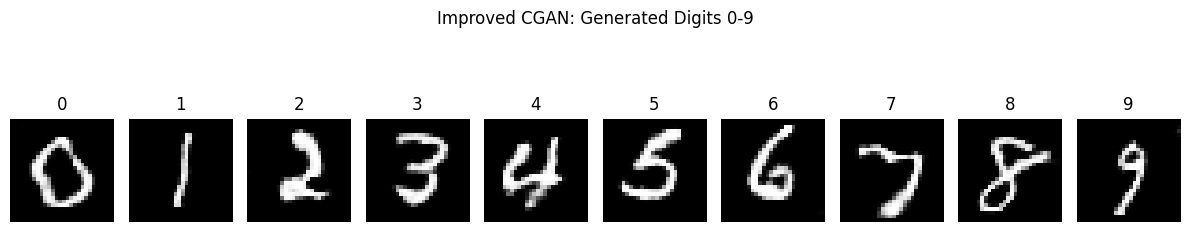

Generator saved successfully!


In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers

# 1. Load MNIST dataset
(x_train, y_train), (_, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 127.5 - 1.0
x_train = x_train[..., np.newaxis]
y_train = y_train.astype("int32")

print("Dataset loaded:", x_train.shape)

# 2. Parameters
latent_dim = 100
num_classes = 10
batch_size = 128
epochs = 30

# 3. Conditional Generator
noise_input = layers.Input(shape=(latent_dim,))
label_input = layers.Input(shape=(1,), dtype="int32")

label_embedding = layers.Embedding(num_classes, 50)(label_input)
label_embedding = layers.Flatten()(label_embedding)

x = layers.Concatenate()([noise_input, label_embedding])
x = layers.Dense(7 * 7 * 128, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Reshape((7, 7, 128))(x)

x = layers.Conv2DTranspose(
    64, 4, strides=2, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(0.2)(x)

image_output = layers.Conv2DTranspose(
    1, 4, strides=2, padding="same", activation="tanh"
)(x)

generator = tf.keras.Model(
    [noise_input, label_input], image_output
)

# 4. Conditional Discriminator
image_input = layers.Input(shape=(28, 28, 1))
disc_label_input = layers.Input(shape=(1,), dtype="int32")

label_embedding = layers.Embedding(
    num_classes, 28 * 28
)(disc_label_input)
label_embedding = layers.Reshape((28, 28, 1))(label_embedding)

x = layers.Concatenate(axis=-1)(
    [image_input, label_embedding]
)

x = layers.Conv2D(64, 4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)

x = layers.Conv2D(128, 4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)

x = layers.Flatten()(x)
output = layers.Dense(1)(x)  # Logit output

discriminator = tf.keras.Model(
    [image_input, disc_label_input], output
)

# 5. Losses and optimizers
loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)

g_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
d_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

# 6. Training step
@tf.function
def train_step(real_images, labels):
    batch = tf.shape(real_images)[0]
    noise = tf.random.normal((batch, latent_dim))

    # Train discriminator
    with tf.GradientTape() as d_tape:
        fake_images = generator([noise, labels], training=True)

        real_logits = discriminator(
            [real_images, labels], training=True
        )
        fake_logits = discriminator(
            [tf.stop_gradient(fake_images), labels],
            training=True
        )

        d_loss_real = loss_fn(
            tf.ones_like(real_logits) * 0.9, real_logits
        )
        d_loss_fake = loss_fn(
            tf.zeros_like(fake_logits), fake_logits
        )
        d_loss = d_loss_real + d_loss_fake

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )
    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    # Train generator
    noise = tf.random.normal((batch, latent_dim))

    with tf.GradientTape() as g_tape:
        fake_images = generator([noise, labels], training=True)
        fake_logits = discriminator(
            [fake_images, labels], training=False
        )
        g_loss = loss_fn(
            tf.ones_like(fake_logits), fake_logits
        )

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )
    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    return g_loss, d_loss

# 7. Prepare dataset
dataset = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)
dataset = dataset.shuffle(60000).batch(
    batch_size, drop_remainder=True
).prefetch(tf.data.AUTOTUNE)

# 8. Train CGAN
for epoch in range(epochs):
    g_metric = tf.keras.metrics.Mean()
    d_metric = tf.keras.metrics.Mean()

    for real_images, labels in dataset:
        g_loss, d_loss = train_step(real_images, labels)
        g_metric.update_state(g_loss)
        d_metric.update_state(d_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Generator Loss: {g_metric.result().numpy():.4f} | "
        f"Discriminator Loss: {d_metric.result().numpy():.4f}"
    )

print("CGAN training completed!")

# 9. Generate one image for each digit 0-9
noise = tf.random.normal((10, latent_dim))
labels = tf.reshape(tf.range(10, dtype=tf.int32), (10, 1))

generated_images = generator(
    [noise, labels], training=False
)

# 10. Display generated digits
plt.figure(figsize=(12, 3))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    image = (generated_images[i, :, :, 0] + 1) / 2
    plt.imshow(image, cmap="gray", vmin=0, vmax=1)
    plt.title(str(i))
    plt.axis("off")

plt.suptitle("Improved CGAN: Generated Digits 0-9")
plt.tight_layout()
plt.show()

# 11. Save the trained generator
generator.save("/content/cgan_generator.keras")
print("Generator saved successfully!")
